# LeakyVault — build weak AES, then break it

The following notebook contains AES implementations that are careless, and we impersonate an attacker exploiting 5 particular weakness without once using the key.

Below contains the table that summarizes our 5 mistakes and the 5 attacking patterns.

| # | The mistake | What the attacker gets | Lecture link |
|---|---|---|---|
| 1 | ECB mode | sees the picture through the "encryption" | Week 3 |
| 2 | Same nonce reused in CTR | recovers the secret messages | Week 2 |
| 3 | Key made from a weak random generator | recovers the **key** | Week 2 / 6 |
| 4 | CBC lock that leaks "padding ok?" | decrypts a file byte-by-byte | Week 3 |
| 5 | CBC has no integrity check | edits the encrypted file | Week 3 |

At the end we switch to **AES-GCM** (the "do-it-right" lock) and show which mistakes it fixes and which it does **not**.

## 0. Setup

We only need `pycryptodome` (AES), plus matplotlib/Pillow for the picture demo.

In [ ]:
# If a package is missing, uncomment the next line and run once:
# !pip install pycryptodome matplotlib pillow

import os
import random
from Crypto.Cipher import AES
from Crypto.Util import Counter

BLOCK = 16  # AES block size is always 16 bytes

# DEMO Mode enforces the same seed for randomness generation, ensuring repeatable runs.
# Set DEMO = False to use real OS randomness.
DEMO = True
DEMO_SEED = 4010
_demo_rng = random.Random(DEMO_SEED)

def rand_bytes(n):
    """Return n random bytes: reproducible in DEMO mode through DEMO_SEED, otherwise from the OS.
    Real code should always use os.urandom (never a seeded generator) for keys."""
    return _demo_rng.randbytes(n) if DEMO else os.urandom(n)


def xor_bytes(a, b):
    """XOR two byte strings together, up to the length of the shorter one."""
    return bytes(x ^ y for x, y in zip(a, b))


def pkcs7_pad(data, block=BLOCK):
    """Add PKCS#7 padding so the length becomes a whole number of blocks.
    If we need N extra bytes, we append the value N, N times."""
    n = block - (len(data) % block)
    return data + bytes([n]) * n


def pkcs7_unpad(data, block=BLOCK):
    """Remove PKCS#7 padding. Raises ValueError if the padding is not valid.
    (That error is exactly the 'leak' the padding-oracle attack will abuse.)"""
    n = data[-1]
    if n < 1 or n > block or data[-n:] != bytes([n]) * n:
        raise ValueError("bad padding")
    return data[:-n]

print(f"Setup done. DEMO mode = {DEMO} (reproducible). AES block size = {BLOCK} bytes.")

Setup done. DEMO mode = True (reproducible). AES block size = 16 bytes.


## 1. The LeakyVault locker

Here is the whole "product". It can lock a file in three AES modes. Each mode is
one line of real AES — the weakness is never in AES, only in how we call it.


In [ ]:
def vault_encrypt_ecb(key, data):
    """Mode 1: ECB. Encrypts each 16-byte block on its own, no diffusion and is deterministic.
    Same input block -> same output block. Revealing patterns from the plain text."""
    return AES.new(key, AES.MODE_ECB).encrypt(pkcs7_pad(data))


def vault_encrypt_ctr(key, nonce8, data):
    """Mode 2: CTR. Turns AES into a stream cipher: it makes a 'keystream'
    from (key, nonce) and XORs it with the data. The nonce MUST be unique."""
    ctr = Counter.new(64, prefix=nonce8, initial_value=0)   # 8-byte nonce + 8-byte counter
    return AES.new(key, AES.MODE_CTR, counter=ctr).encrypt(data)


def vault_encrypt_cbc(key, iv, data):
    """Mode 3: CBC. Chains blocks together using an IV. Needs padding,
    and it has NO integrity check (that is bugs 4 and 5). Meaning, no way to
    authenticate that the cipher hasn't been tampered with."""
    return AES.new(key, AES.MODE_CBC, iv).encrypt(pkcs7_pad(data))


def weak_key_from_seed(seed):
    """BAD key generation: the key is just 16 bytes from Python's random module
    seeded with a small number. A good key would come from os.urandom(16)."""
    r = random.Random(seed)
    return r.getrandbits(128).to_bytes(16, "big")

print("LeakyVault is ready: ECB / CTR / CBC, plus a (deliberately) weak key maker.")

LeakyVault is ready: ECB / CTR / CBC, plus a (deliberately) weak key maker.


## 2. Bug #1 — ECB mode leaks patterns in the picture

ECB encrypts every 16-byte block independently with no diffusion, so **identical blocks of the original become identical blocks of the ciphertext**. 

A picture has big areas of one colour, so its shape survives "encryption". No computation is needed attack this.

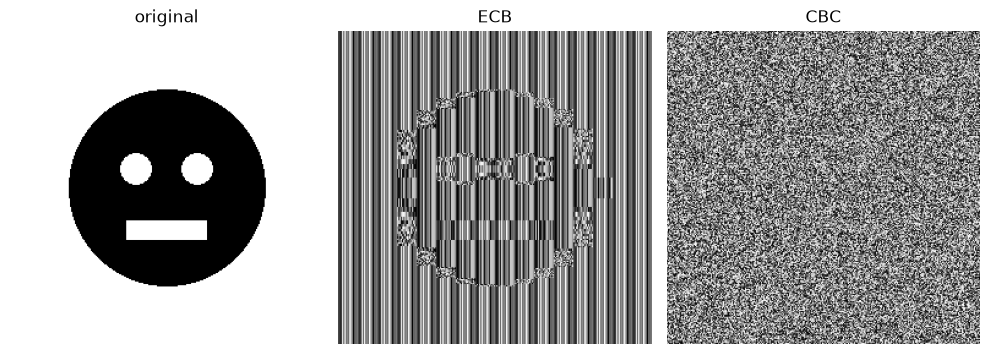

In [15]:
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# --- make a simple high-contrast picture (big solid regions) ---
def make_picture():
    """Draw a simple face on a 256x256 grey image. Big solid areas are what
    makes the ECB leak visible."""
    img = Image.new("L", (256, 256), color=255)      # white background
    d = ImageDraw.Draw(img)
    d.ellipse([48, 48, 208, 208], fill=40)           # face (dark)
    d.ellipse([90, 100, 115, 125], fill=255)         # left eye
    d.ellipse([140, 100, 165, 125], fill=255)        # right eye
    d.rectangle([95, 155, 160, 170], fill=255)       # mouth
    return img

pic = make_picture()
raw = pic.tobytes()                                   # 256*256 = 65536 bytes
key = rand_bytes(16)

# Encrypt the raw pixels two ways: ECB and CBC
ecb_bytes = AES.new(key, AES.MODE_ECB).encrypt(raw)              # no padding needed (multiple of 16)
cbc_bytes = AES.new(key, AES.MODE_CBC, rand_bytes(16)).encrypt(raw)

# Turn the ciphertext bytes back into pictures so we can SEE them
ecb_img = Image.frombytes("L", (256, 256), ecb_bytes)
cbc_img = Image.frombytes("L", (256, 256), cbc_bytes)

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
for a, im, t in zip(ax, [pic, ecb_img, cbc_img],
                    ["original", "ECB", "CBC"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

In [16]:
# We can also DETECT ECB statistically as real encryption should have no repeated blocks.
def count_repeated_blocks(ciphertext):
    """Count how many 16-byte blocks are duplicates. 0 = good, more = ECB-like."""
    blocks = [ciphertext[i:i+BLOCK] for i in range(0, len(ciphertext), BLOCK)]
    return len(blocks) - len(set(blocks))

print("Repeated blocks in ECB:", count_repeated_blocks(ecb_bytes))
print("Repeated blocks in CBC:", count_repeated_blocks(cbc_bytes))

Repeated blocks in ECB: 4060
Repeated blocks in CBC: 0


## 3. Bug #2 — reusing the nonce in CTR (the "two-time pad")

CTR makes a keystream from `(key, nonce)` and XORs it with the file. If LeakyVault
uses the **same nonce** for two files, both get the **same keystream**:

$$C_1 = P_1 \oplus KS \qquad C_2 = P_2 \oplus KS \qquad C_1 \oplus C_2 = P_1 \oplus P_2$$

The key cancels out completely. First we show that identity, then we recover the
real messages.


In [19]:
key   = rand_bytes(16)
nonce = rand_bytes(8)                      # ONE nonce, reused on purpose

m1 = b"attack at dawn from the north ridge"
m2 = b"the gold is hidden under the bridge"

c1 = vault_encrypt_ctr(key, nonce, m1)
c2 = vault_encrypt_ctr(key, nonce, m2)

# Attacker XORs the two ciphertexts. The keystream disappears.
print("C1 XOR C2 == P1 XOR P2 ?", xor_bytes(c1, c2) == xor_bytes(m1, m2))

# If the attacker GUESSES (or knows) one message, the other falls out for free:
guess_m1 = b"attack at dawn from the north ridge"
print("Recovered m2 from a guessed m1:", xor_bytes(xor_bytes(c1, c2), guess_m1))

C1 XOR C2 == P1 XOR P2 ? True
Recovered m2 from a guessed m1: b'the gold is hidden under the bridge'


### Crib dragging — what if we didn't have a full m1?

The cell above cheats a little: it guesses **all** of $P_1$ correctly. A real attacker probably can't, but they don't need to. All they need is $X = C_1 \oplus C_2 = P_1 \oplus P_2$ and the fact that both files are English.

1. **Find the spaces.** In ASCII, a space ' ' XOR a letter is the same letter with its case flipped, while two lowercase letters XOR to a non-letter. So every letter in $X$ marks a spot where one of the two messages has a space, which shows the word boundaries for free.
2. **Drag a crib.** Pick a likely word such as `" the "`, XOR it into $X$ at every position, and look at the result. If the crib really sits in one message at that position, the other message's text appears. Otherwise the result is usually junk. Some hits are noise (`'aepl'`), and near the end the two messages share `"ridge"`, so $X$ is zero there and the crib just echoes back (`'bthe '`). The attacker throws those out by eye.
3. **Grow the fragments.** Each hit is a matched pair of fragments. Finish the
   word in one message, XOR it in, and the other message grows. Then switch sides
   and repeat until both messages are recovered.

The attacker never needs a whole message, only common words and the patience to
extend them. With **many** messages under the same nonce, even the guessing goes
away, as the next cell shows.

In [23]:
# Crib dragging: the attacker knows NOTHING about either message, only that both
# are English. All they have is X = C1 XOR C2 = P1 XOR P2 (the key is gone).
X = xor_bytes(c1, c2)

# --- Step 1: a free hint. Space XOR letter = the same letter with its case flipped,
# but letter XOR letter is never a letter. So a letter in X means one message has a SPACE there.
# this way, we can easily draw out word boundaries.
print("Step 1 - find word boundaries?")
print("   X as text :", "".join(chr(b) if chr(b).isalpha() else "." for b in X))
print("   spaces    :", "".join("^" if chr(b).isalpha() else " " for b in X))


# --- Step 2: drag common words (cribs) across X ---
def looks_like_text(bs):
    """True if every byte is a lowercase letter or a space."""
    return all(b == 0x20 or 97 <= b <= 122 for b in bs)


sampler = random.Random(DEMO_SEED)   # own generator for picking rows to print: same picks every run,
                                     # and it doesn't touch the global `random` that §4b relies on

def drag(crib, X, show=0):
    """Slide the crib along X. Where the crib really sits in ONE message, XOR-ing it
    in shows the OTHER message's text. Keep only results that look like English.
    show=N prints N random positions (one accepted, the rest rejected) to see the filter at work."""
    hits, tried = [], []
    for i in range(len(X) - len(crib) + 1):
        window = X[i:i + len(crib)]
        if not any(window):          # both messages identical here, the crib just echoes back
            continue
        out = xor_bytes(window, crib)
        ok = looks_like_text(out)
        tried.append((i, window, out, ok))
        if ok:
            hits.append((i, out))
    if show:
        accepted = [t for t in tried if t[3]]
        rejected = [t for t in tried if not t[3]]
        picks = (sampler.sample(accepted, min(1, len(accepted)))
                 + sampler.sample(rejected, min(show - 1, len(rejected))))
        for i, window, out, ok in sorted(picks):
            print(f"      pos {i:2d}: X window {window!r:24} XOR crib -> {out!r:10} looks like text: {ok}")
    return hits


print("\nStep 2 - drag common words across X:")
for crib in [b"the ", b" the ", b" at ", b" is "]:
    print(f"   crib {crib.decode()!r}  (a random sample of the positions tried)")
    hits = drag(crib, X, show=3)
    print("      hits:", ", ".join(f"pos {i}: {out.decode()!r}" for i, out in hits))


# --- Step 3: grow the fragments. Each guess in one message reveals the other. ---
A = bytearray(b"." * len(X))         # we don't know which is m1, so call them A and B
B = bytearray(b"." * len(X))

def place(text, into):
    """Write a guess at the START of message A or B; X fills in the other one."""
    mine, other = (A, B) if into == "A" else (B, A)
    mine[:len(text)] = text
    other[:len(text)] = xor_bytes(X, text)

guesses = [                          # each guess just finishes the word the last step exposed
    ("B", b"the "),                  # from step 2: 'the ' at pos 0 gave 'atta'
    ("A", b"attack at "),
    ("B", b"the gold is "),
    ("A", b"attack at dawn "),
    ("B", b"the gold is hidden "),
    ("A", b"attack at dawn from the "),
    ("B", b"the gold is hidden under the "),
    ("A", b"attack at dawn from the north "),
    ("B", b"the gold is hidden under the bridge"),
]

print("\nStep 3 - grow the fragments, one word at a time:")
for n, (into, text) in enumerate(guesses, 1):
    place(text, into)
    print(f"   {n}. guess {into}  A: {A.decode()}")
    print(f"               B: {B.decode()}")

print("\nRecovered both messages:", {bytes(A), bytes(B)} == {m1, m2})

Step 1 - find word boundaries?
   X as text : ...A..L.TI.A..D...MU...RN...HB.....
   spaces    :    ^  ^ ^^ ^  ^   ^^   ^^   ^^     

Step 2 - drag common words across X:
   crib 'the '  (a random sample of the positions tried)
      pos  5: X window b'\x04L\x05T'            XOR crib -> b'p$`t'    looks like text: False
      pos  9: X window b'I\x17A\x1f'            XOR crib -> b'=\x7f$?' looks like text: False
      pos 25: X window b'\x1b\x1a\x11H'         XOR crib -> b'orth'    looks like text: True
      hits: pos 0: 'atta', pos 20: 'nder', pos 25: 'orth'
   crib ' the '  (a random sample of the positions tried)
      pos  9: X window b'I\x17A\x1f\x07'        XOR crib -> b"ic)z'"   looks like text: False
      pos 21: X window b'\x0c\x00RN\x1b'        XOR crib -> b',t:+;'   looks like text: False
      pos 29: X window b'B\x00\x00\x00\x00'     XOR crib -> b'bthe '   looks like text: True
      hits: pos 19: 'under', pos 24: 'north', pos 29: 'bthe '
   crib ' at '  (a random sample

In [6]:
# The real attack with NO guesses: the "many-time pad".
# If the same nonce is reused across MANY files, we recover them all automatically.
# Trick: in English, space (0x20) XOR a letter = that letter with its case flipped,
# which is still a letter. So the column where a message has a space stands out.

messages = [
    b"the quick brown fox jumps over the lazy dog again and again",
    b"we hold these truths to be self evident that all are equal",
    b"cryptography is the art of keeping secret messages secret!",
    b"never reuse a nonce with the same key or you leak the pad.",
    b"attack at dawn from the north ridge and bring the ladders",
    b"the treasure is buried under the old oak tree near the well",
    b"please remember to buy milk bread eggs and coffee tomorrow",
    b"a wise person once said measure twice and then cut once ok",
    b"the meeting is moved to three pm in the big room upstairs!",
    b"my password is not written down anywhere except in my head",
    b"roses are red violets are blue this cipher is broken and so",
    b"send reinforcements we are going to advance on the hilltop",
]

# LeakyVault locks every message with the SAME nonce (the bug)
ciphertexts = [vault_encrypt_ctr(key, nonce, m) for m in messages]


def is_letter(b):
    """True if the byte is an ASCII letter A-Z or a-z."""
    return (65 <= b <= 90) or (97 <= b <= 122)


def recover_keystream(cts):
    """Recover the shared keystream column by column.
    For each column we find the message most likely to have a space there
    (its byte XORed with the others gives letters most often)."""
    length = min(len(c) for c in cts)
    keystream = bytearray(length)
    confidence = [0] * length
    for j in range(length):
        best_count, best_byte = -1, 0
        for i in range(len(cts)):
            count = sum(1 for k in range(len(cts))
                        if k != i and is_letter(cts[i][j] ^ cts[k][j]))
            if count > best_count:
                best_count = count
                best_byte = cts[i][j] ^ 0x20     # assume message i has a space here
        keystream[j] = best_byte
        confidence[j] = best_count
    return keystream, confidence


keystream, confidence = recover_keystream(ciphertexts)
threshold = len(ciphertexts) // 3   # columns below this are "not sure"

print("Recovered messages ('.' = a column we are unsure about):\n")
for i, c in enumerate(ciphertexts):
    out = ""
    for j in range(len(keystream)):
        ch = c[j] ^ keystream[j]
        out += chr(ch) if confidence[j] >= threshold and 32 <= ch < 127 else "."
    print(f"{i:2d}: {out}")

Recovered messages ('.' = a column we are unsure about):

 0: .he quic. .rown ..x jumps over the lazy dog again a.d aga
 1: .e hold .h.se tr..hs to be self evident that all ar. equa
 2: .ryptogr.p.y is ..e art of keeping secret messages .ecret
 3: .ever re.s. a no..e with the same key or you leak t.e pad
 4: .ttack a. .awn f..m the north ridge and bring the l.dders
 5: .he trea.u.e is ..ried under the old oak tree near .he we
 6: .lease r.m.mber .. buy milk bread eggs and coffee t.morro
 7: . wise p.r.on on.. said measure twice and then cut .nce o
 8: .he meet.n. is m..ed to three pm in the big room up.tairs
 9: .y passw.r. is n.. written down anywhere except in .y hea
10: .oses ar. .ed vi..ets are blue this cipher is broke. and 
11: .end rei.f.rceme..s we are going to advance on the .illto


## 4. Bug #3 — the key comes from a weak random generator

A key is only as good as the randomness behind it. Python's `random` module is a
Mersenne Twister (MT). Its period is enormous ($2^{19937}-1$, far more than
$2^{128}$), so **a long period is not the problem**. Two other things are:

- **Too little entropy in the seed.** If the generator is seeded with a small
  number, the whole key is decided by that number, so the attacker searches the
  *seeds*, not the $2^{128}$ keys (§4a).
- **Predictable outputs.** MT is not a CSPRNG: its outputs are an invertible
  function of its internal state, so seeing enough outputs reveals the state and
  every future output (§4b).

A cryptographically secure generator (`os.urandom` / `secrets`) avoids both. We
show that at the end, in §4c.

### 4a. Key from a small seed — brute force

LeakyVault seeds the generator with a small number (imagine a cheap device that
seeds from a counter or the clock). The whole key is then decided by that seed,
so the attacker just tries every seed.


In [7]:
true_seed = 48271                         # a small secret seed inside the device
key = weak_key_from_seed(true_seed)
iv  = b"\x00" * 16
secret_file = b"Transfer $5000 to account 12345"
locked = vault_encrypt_cbc(key, iv, secret_file)

# Attacker tries seeds until the padding comes out valid AND the text looks sane.
def brute_force_seed(ciphertext, iv, max_seed=100000):
    """Try seeds 0..max_seed; return the first key that decrypts cleanly."""
    for s in range(max_seed):
        guess = weak_key_from_seed(s)
        try:
            pt = pkcs7_unpad(AES.new(guess, AES.MODE_CBC, iv).decrypt(ciphertext))
            if all(32 <= b < 127 for b in pt):      # looks like normal text
                return s, pt
        except ValueError:
            pass
    return None, None

found_seed, recovered = brute_force_seed(locked, iv)
print("Attacker found the seed:", found_seed)
print("Decrypted file        :", recovered)

Attacker found the seed: 48271
Decrypted file        : b'Transfer $5000 to account 12345'


### 4b. Mersenne Twister state recovery — predict the key

Python's `random` is a Mersenne Twister. It is **not** cryptographic: if we see
624 of its raw 32-bit outputs, we can rebuild its whole internal state and then
**predict every future number** — including the next key it makes.

Here LeakyVault leaks outputs by using them as public "file IDs", then uses the
*next* output as a secret key.


In [8]:
# --- reverse the MT "tempering" step (turns one output back into one state word) ---
def undo_rshift_xor(y, shift):
    """Invert  y = x ^ (x >> shift)  for a 32-bit number x."""
    x = 0
    for bit in range(31, -1, -1):          # rebuild x from the top bit down
        src = bit + shift
        known = (x >> src) & 1 if src <= 31 else 0
        x |= (((y >> bit) & 1) ^ known) << bit
    return x & 0xFFFFFFFF

def undo_lshift_and_xor(y, shift, mask):
    """Invert  y = x ^ ((x << shift) & mask)  for a 32-bit number x."""
    x = 0
    for bit in range(32):                  # rebuild x from the bottom bit up
        src = bit - shift
        known = (x >> src) & 1 if src >= 0 else 0
        x |= (((y >> bit) & 1) ^ (known & ((mask >> bit) & 1))) << bit
    return x & 0xFFFFFFFF

def untemper(y):
    """Undo all four tempering steps -> one word of internal MT state."""
    y = undo_rshift_xor(y, 18)
    y = undo_lshift_and_xor(y, 15, 0xEFC60000)
    y = undo_lshift_and_xor(y, 7, 0x9D2C5680)
    y = undo_rshift_xor(y, 11)
    return y

In [9]:
# The device starts from a (truly random, or fixed in DEMO) point,
# then leaks 624 outputs as public "file IDs"
random.seed(DEMO_SEED if DEMO else os.urandom(16))
public_file_ids = [random.getrandbits(32) for _ in range(624)]   # attacker can see these

# ...and then builds the next key from the VERY NEXT outputs (the secret)
secret_key_words = [random.getrandbits(32) for _ in range(4)]    # 4 x 32 = 128-bit key
real_key = b"".join(w.to_bytes(4, "big") for w in secret_key_words)

# Attacker: untemper the 624 public outputs to clone the generator state
state = [untemper(x) for x in public_file_ids]
clone = random.Random()
clone.setstate((3, tuple(state + [624]), None))

# Predict the next 4 outputs -> the key
predicted_words = [clone.getrandbits(32) for _ in range(4)]
predicted_key = b"".join(w.to_bytes(4, "big") for w in predicted_words)

print("Real key     :", real_key.hex())
print("Predicted key:", predicted_key.hex())
print("Key recovered :", predicted_key == real_key)

Real key     : 2ac695131cfac7aa8c61e7ea4799226f
Predicted key: 2ac695131cfac7aa8c61e7ea4799226f
Key recovered : True


### 4c. The counterexample — same attacks against a CSPRNG key

Now the device does it right: keys (and file IDs) come from `secrets`, which reads
the operating system's cryptographically secure generator. We run the **exact
same two attacks** again.

- **4a fails** because there is no small seed to search. The only option left is
  trying all $2^{128}$ keys, and we time our own brute-force loop to see how long
  that would take.
- **4b fails** because CSPRNG outputs don't reveal any internal state. Untempering
  them gives a meaningless "state", and the clone predicts the wrong key.

This cell ignores `DEMO` on purpose (it calls `secrets` directly), so the keys
change every run. The result, attack fails, does not.

In [10]:
import secrets, time

# --- 4a again: the key now comes from the OS CSPRNG, so there is no small seed ---
good_key = secrets.token_bytes(16)
locked_good = vault_encrypt_cbc(good_key, iv, secret_file)    # same file, same IV as 4a

t0 = time.time()
found_seed, _ = brute_force_seed(locked_good, iv)             # the exact same attack
rate = 100000 / (time.time() - t0)                            # keys tried per second

print("4a vs CSPRNG key")
print("   Seed search found      :", found_seed, " <- nothing to find")
print(f"   Our brute-force speed  : {rate:,.0f} keys/s")
print(f"   Time to try all 2^128  : ~{2**128 / rate / 3.15e7:.1e} years")

# --- 4b again: the file IDs and the key both come from the CSPRNG ---
csprng_file_ids = [int.from_bytes(secrets.token_bytes(4), "big") for _ in range(624)]
real_key = secrets.token_bytes(16)

state = [untemper(x) for x in csprng_file_ids]                # the exact same attack
clone = random.Random()
clone.setstate((3, tuple(state + [624]), None))
predicted_key = b"".join(clone.getrandbits(32).to_bytes(4, "big") for _ in range(4))

print("\n4b vs CSPRNG key")
print("   Real key     :", real_key.hex())
print("   Predicted key:", predicted_key.hex())
print("   Key recovered :", predicted_key == real_key, " <- the clone is useless")

4a vs CSPRNG key
   Seed search found      : None  <- nothing to find
   Our brute-force speed  : 38,169 keys/s
   Time to try all 2^128  : ~2.8e+26 years

4b vs CSPRNG key
   Real key     : 22ee4d6ece430af02ca809508d12893b
   Predicted key: ae46254ebb721de594b6568cc1cd6978
   Key recovered : False  <- the clone is useless


## 5. Bug #4 — the CBC padding oracle (the showpiece)

In CBC, each plaintext block is $P_i = D(C_i) \oplus C_{i-1}$. If LeakyVault ever
reveals **whether the padding was valid** (an error message, or just a different
crash), that single yes/no is enough to decrypt the whole file **without the key**.
We change the previous block one byte at a time and watch the oracle.


In [11]:
# The victim locks a file. The attacker only gets to ask the oracle yes/no questions.
victim_key = rand_bytes(16)
victim_iv  = rand_bytes(16)
secret_msg = b"Meet me at pier 7 at midnight. Bring the documents."
ciphertext = vault_encrypt_cbc(victim_key, victim_iv, secret_msg)

def padding_oracle(iv, ct):
    """The LEAK: returns True if the decrypted padding is valid, else False.
    This is the only thing the attacker can see."""
    pt = AES.new(victim_key, AES.MODE_CBC, iv).decrypt(ct)
    try:
        pkcs7_unpad(pt)
        return True
    except ValueError:
        return False

In [12]:
def attack_one_block(prev_block, target_block):
    """Recover one 16-byte plaintext block using only the yes/no oracle."""
    inter = bytearray(16)        # D(target_block): the cipher output before XOR
    forged = bytearray(16)       # a fake "previous block" we control
    for pad in range(1, 17):             # recover last byte, then 2nd last, ...
        idx = 16 - pad
        # make the already-known tail decrypt to the padding value 'pad'
        for k in range(idx + 1, 16):
            forged[k] = inter[k] ^ pad
        for guess in range(256):
            forged[idx] = guess
            if padding_oracle(bytes(forged), target_block):
                # extra check for the last byte, to avoid a false 0x01-vs-0x02 match
                if pad == 1:
                    forged[idx - 1] ^= 0xFF
                    ok = padding_oracle(bytes(forged), target_block)
                    forged[idx - 1] ^= 0xFF
                    if not ok:
                        continue
                inter[idx] = guess ^ pad     # we learned one byte of D(target_block)
                break
    # plaintext = D(target_block) XOR real previous block
    return bytes(inter[i] ^ prev_block[i] for i in range(16))


# Walk through every block (the IV acts as the "previous block" for block 1)
blocks = [victim_iv] + [ciphertext[i:i+16] for i in range(0, len(ciphertext), 16)]
recovered = b""
for i in range(1, len(blocks)):
    recovered += attack_one_block(blocks[i-1], blocks[i])

print("Recovered WITHOUT the key:")
print("   ", pkcs7_unpad(recovered))

Recovered WITHOUT the key:
    b'Meet me at pier 7 at midnight. Bring the documents.'


## 6. Bug #5 — CBC has no integrity (the bit-flip)

CBC keeps your message secret but does **not** stop someone changing it. Because
the first plaintext block is $P_0 = D(C_0) \oplus IV$, flipping a bit in the IV
flips the matching bit in the message — no key needed. Classic example: turning
`admin=0` into `admin=1`.


In [13]:
key = rand_bytes(16)
iv  = rand_bytes(16)

token = b"admin=0;id=00001"          # exactly 16 bytes = one block
locked = AES.new(key, AES.MODE_CBC, iv).encrypt(token)

# Attacker never decrypts it. They just flip the right bit in the IV.
pos   = token.index(b"0")             # position of the '0' after 'admin='
delta = ord("0") ^ ord("1")          # the XOR that turns '0' into '1'
evil_iv = bytearray(iv)
evil_iv[pos] ^= delta

# When the app opens it with the tampered IV:
opened = AES.new(key, AES.MODE_CBC, bytes(evil_iv)).decrypt(locked)
print("Original token :", token)
print("Tampered token :", opened, " <- we are admin now")

Original token : b'admin=0;id=00001'
Tampered token : b'admin=1;id=00001'  <- we are admin now


## 7. The honest conclusion — does AES-GCM fix it?

**GCM** is the "do-it-right" mode: it encrypts *and* adds an authentication tag.
The tempting claim is "GCM fixes everything." That is **false**, and this honesty
is the strongest part of the talk.


In [14]:
# GCM kills the padding oracle and the bit-flip: tampering is REJECTED.
key = rand_bytes(16); nonce = rand_bytes(12)
ct, tag = AES.new(key, AES.MODE_GCM, nonce=nonce).encrypt_and_digest(b"balance=100")
bad = bytearray(ct); bad[0] ^= 1                     # attacker flips a bit
try:
    AES.new(key, AES.MODE_GCM, nonce=nonce).decrypt_and_verify(bytes(bad), tag)
    print("tamper accepted (bad)")
except ValueError:
    print("GCM vs bit-flip : REJECTED  -> integrity works")

# BUT GCM is ALSO broken by nonce reuse: same nonce -> same keystream -> two-time pad.
key = rand_bytes(16); nonce = rand_bytes(12)
p1 = b"attack at dawn!!"; p2 = b"retreat at noon!"
c1 = AES.new(key, AES.MODE_GCM, nonce=nonce).encrypt(p1)
c2 = AES.new(key, AES.MODE_GCM, nonce=nonce).encrypt(p2)
print("GCM vs nonce reuse: C1^C2 == P1^P2 ?", xor_bytes(c1, c2) == xor_bytes(p1, p2),
      " -> STILL BROKEN (and the auth key leaks too)")

GCM vs bit-flip : REJECTED  -> integrity works
GCM vs nonce reuse: C1^C2 == P1^P2 ? True  -> STILL BROKEN (and the auth key leaks too)


### What GCM does and does not fix

| The bug | Does switching to AES-GCM fix it? |
|---|---|
| #1 ECB pattern leak | **Yes** — GCM uses a counter inside, no repeated blocks |
| #4 CBC padding oracle | **Yes** — no padding, and the tag is checked first |
| #5 CBC bit-flip | **Yes** — the tag rejects any change |
| #2 Nonce reuse | **No — worse**: keystream repeats *and* the auth key leaks (forgery) |
| #3 Weak random key | **No** — key quality lives *below* the mode |

**The one-line lesson for the talk:** *bad randomness is the root of evil.* It
breaks the key (bug 3) and, if it feeds the nonce, it breaks even GCM (bug 2). A
good mode fixes careless **structure**; it cannot fix bad **randomness**. That is
why misuse-resistant modes like **AES-GCM-SIV** exist.


## 8. README — for submission

**Project:** LeakyVault — build a weak AES file-locker, then break it five ways
without the key, and end with an honest look at AES-GCM.

**Team:** _your name_ + _buddy's name_ (group of 2).

**How to run:** open in Jupyter and `Cell -> Run All`, top to bottom. Each section
is self-contained. `DEMO = True` (in Section 0) makes every run reproducible; set
it to `False` for fresh OS randomness. (§4c always uses fresh OS randomness, so its
keys change each run, but the attacks always fail.)

**Dependencies:** `pip install pycryptodome matplotlib pillow` (Python 3.9+).

**Map of each attack — section, lecture, why it works, and the fix:**

| Attack | Section | Lecture | Why it works | The fix |
|---|---|---|---|---|
| ECB pattern leak | §2 | Week 3 | identical plaintext blocks → identical ciphertext blocks | a randomized mode (CTR/CBC) or GCM |
| Nonce reuse (two-time pad) | §3 | Week 2 | same nonce → same keystream → XOR cancels the key | a unique nonce per message; GCM-SIV if reuse is possible |
| Weak key: seed brute force | §4a | Week 2 / 6 | the whole key is decided by a tiny seed | derive the key from `os.urandom` / a CSPRNG |
| Weak key: MT state recovery | §4b | Week 2 | Mersenne Twister is predictable from 624 outputs | never use `random` for keys; use `secrets` / `os.urandom` |
| *(counterexample)* CSPRNG key | §4c | Week 2 / 6 | — both §4a and §4b fail against a `secrets` key | — |
| CBC padding oracle | §5 | Week 3 | a "padding valid?" signal leaks the plaintext | authenticated encryption (GCM); don't reveal padding errors |
| CBC bit-flip | §6 | Week 3 | CBC gives no integrity, only secrecy | authenticated encryption (GCM) |

**Suggested buddy split:** Partner A owns LeakyVault + §2, §3, §4 (bad modes and
bad randomness); Partner B owns §5 (the padding oracle) end-to-end. Both rehearse
the two-time-pad XOR and the CBC equation for Q&A.
